<a href="https://colab.research.google.com/github/TokaElsaayed/Deep-project/blob/transfer-learning/DLproj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi


Tue Oct 27 22:12:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
import torchvision
import matplotlib
import yaml

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!git clone --branch transfer-learning --single-branch https://github.com/TokaElsayaed/Deep-project.git /content/Deep-project

Cloning into '/content/Deep-project'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!git clone --branch transfer-learning --single-branch \
  https://github.com/TokaElsayaed/Deep-project.git \
  /content/Deep-project


Cloning into '/content/Deep-project'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!git clone --branch transfer-learning --single-branch \
  https://github.com/TokaElsaayed/Deep-project.git \
  /content/Deep-project

Cloning into '/content/Deep-project'...
fatal: Remote branch transfer-learning not found in upstream origin


In [ ]:
!git ls-remote --heads https://github.com/TokaElsaayed/Deep-project.git

d09169c42dd7e1185f6172eee94eed9851a5b514	refs/heads/main
2427bb4929df0a3a9eb8fd55c5129b7c30b72018	refs/heads/person1-baseline-cnn


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving transfer-learning.zip to transfer-learning.zip


In [ ]:
import zipfile
import os

zip_path = "/content/transfer-learning.zip"
extract_path = "/content/Deep-project"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Project files extracted to:", extract_path)
print(os.listdir(extract_path))

Project files extracted to: /content/Deep-project
['README.md', 'baseline_cnn.ipynb', 'src', 'requirements.txt', 'notebooks', 'tests', 'configs', 'baseline_cnn_complete.py', 'outputs', '.gitignore']


In [ ]:
%cd /content/Deep-project

!find . -maxdepth 3 -type f | sort

/content/Deep-project
./baseline_cnn_complete.py
./baseline_cnn.ipynb
./configs/eda.yaml
./.gitignore
./notebooks/01_load_data.ipynb
./outputs/baseline/README.md
./outputs/baseline/training_curves.png
./outputs/eda/augmentation_examples.png
./outputs/eda/caption_cleaning_summary.csv
./outputs/eda/caption_quality.csv
./outputs/eda/caption_statistics.png
./outputs/eda/class_counts.csv
./outputs/eda/class_distribution.png
./outputs/eda/confirmed_duplicate_removals.csv
./outputs/eda/confirmed_perceptual_removals.csv
./outputs/eda/corrupt_images.csv
./outputs/eda/duplicate_images.csv
./outputs/eda/image_dimensions.png
./outputs/eda/image_quality.png
./outputs/eda/perceptual_duplicate_pairs.csv
./outputs/eda/perceptual_duplicate_pairs_final.csv
./outputs/eda/perceptual_duplicate_review_final.png
./outputs/eda/perceptual_duplicate_review.png
./outputs/eda/splits.csv
./outputs/eda/test_class_distribution.png
./outputs/eda/typo_candidates.csv
./outputs/eda/vocabulary.csv
./README.md
./requireme

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving transfer-learning-latest.zip to transfer-learning-latest.zip


In [ ]:
import os
import zipfile

zip_path = "/content/transfer-learning-latest.zip"
project_path = "/content/Deep-project"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(project_path)

print("Latest transfer-learning files copied successfully.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/transfer-learning-latest.zip'

In [ ]:
import os

for folder in ["/content", "/content/Deep-project"]:
    print(f"\nChecking {folder}:")
    if os.path.exists(folder):
        print(os.listdir(folder))


Checking /content:
['.config', 'Deep-project', 'transfer-learning.zip', 'sample_data']

Checking /content/Deep-project:
['transfer-learning-latest.zip', 'README.md', 'baseline_cnn.ipynb', 'src', 'requirements.txt', 'notebooks', 'tests', 'configs', 'baseline_cnn_complete.py', 'outputs', '.gitignore']


In [ ]:
import zipfile
import os

zip_path = "/content/Deep-project/transfer-learning-latest.zip"
project_path = "/content/Deep-project"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files in ZIP:")
    for name in z.namelist():
        print(name)

    z.extractall(project_path)

print("\nExtraction completed!")

Files in ZIP:
src\cli.py
src\data\clean_phase2.py
src\data\eda.py
src\data\near_duplicates.py
src\data\transfer_dataset.py
src\data\transforms.py
src\data\__init__.py
src\data\__pycache__\clean_phase2.cpython-37.pyc
src\data\__pycache__\eda.cpython-37.pyc
src\data\__pycache__\near_duplicates.cpython-37.pyc
src\data\__pycache__\transfer_dataset.cpython-37.pyc
src\data\__pycache__\transforms.cpython-37.pyc
src\data\__pycache__\__init__.cpython-37.pyc
src\models\baseline_cnn.py
src\models\transfer_learning.py
src\models\__pycache__\baseline_cnn.cpython-37.pyc
src\models\__pycache__\transfer_learning.cpython-37.pyc
src\training\train_baseline.py
src\training\transfer_learning.py
src\training\__pycache__\train_baseline.cpython-37.pyc
src\training\__pycache__\transfer_learning.cpython-37.pyc
src\__pycache__\cli.cpython-37.pyc
configs\eda.yaml
configs\transfer_learning.yaml
tests\test_clean_phase2.py
tests\test_transfer_learning.py
tests\test_transforms.py
tests\__pycache__\test_clean_phase2.

In [ ]:
%cd /content/Deep-project

print("===== TRANSFER LEARNING CONFIG =====")
with open("configs/transfer_learning.yaml", "r") as f:
    print(f.read())

print("\n===== DATASET LOADER =====")
with open("src/data/transfer_dataset.py", "r") as f:
    print(f.read())

/content/Deep-project
===== TRANSFER LEARNING CONFIG =====


FileNotFoundError: [Errno 2] No such file or directory: 'configs/transfer_learning.yaml'

In [ ]:
import os
import zipfile

zip_path = "/content/Deep-project/transfer-learning-latest.zip"
project_path = "/content/Deep-project"

assert os.path.isfile(zip_path), f"ZIP not found: {zip_path}"

with zipfile.ZipFile(zip_path, "r") as z:
    for member in z.infolist():
        # Convert Windows separators into Linux separators
        clean_name = member.filename.replace("\\", "/")
        target_path = os.path.join(project_path, clean_name)

        if member.is_dir() or clean_name.endswith("/"):
            os.makedirs(target_path, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target_path), exist_ok=True)
            with z.open(member) as source, open(target_path, "wb") as target:
                target.write(source.read())

print("Extraction repaired!")

Extraction repaired!


In [ ]:
import os

project_path = "/content/Deep-project"

files_to_check = [
    "configs/transfer_learning.yaml",
    "src/data/transfer_dataset.py",
    "src/models/transfer_learning.py",
    "src/training/transfer_learning.py",
    "tests/test_transfer_learning.py",
    "TRANSFER_LEARNING.md",
]

for filename in files_to_check:
    path = os.path.join(project_path, filename)
    print(("FOUND  " if os.path.isfile(path) else "MISSING") + filename)

FOUND  configs/transfer_learning.yaml
FOUND  src/data/transfer_dataset.py
FOUND  src/models/transfer_learning.py
FOUND  src/training/transfer_learning.py
FOUND  tests/test_transfer_learning.py
FOUND  TRANSFER_LEARNING.md


In [ ]:
%cd /content/Deep-project

print("===== TRANSFER LEARNING CONFIG =====")
with open("configs/transfer_learning.yaml", "r") as f:
    print(f.read())

print("\n===== DATASET LOADER =====")
with open("src/data/transfer_dataset.py", "r") as f:
    print(f.read())

/content/Deep-project
===== TRANSFER LEARNING CONFIG =====
seed: 42
dataset:
  config: configs/eda.yaml
  splits: outputs/eda/splits.csv
  num_classes: 200
training:
  batch_size: 32
  workers: 0
  feature_extraction:
    epochs: 30
    head_learning_rate: 0.001
    weight_decay: 0.0001
    patience: 7
  fine_tuning:
    epochs: 30
    head_learning_rate: 0.0001
    backbone_learning_rate: 0.00001
    weight_decay: 0.0001
    patience: 7
  fine_tune_backbone_blocks: 1
  mixed_precision: true
outputs_dir: outputs/transfer_learning


===== DATASET LOADER =====
"""CUB dataset view backed by the repository's established split CSV."""

from __future__ import annotations

from pathlib import Path
from typing import Any

import pandas as pd
import yaml
from PIL import Image
from torch.utils.data import Dataset

from src.data.eda import _image_object, load_cub_datasets


class CUBTransferDataset(Dataset):
    """Read split membership from CSV and image records from the existing HF loader."""



In [ ]:
%cd /content/Deep-project

print("===== EDA CONFIG =====")
with open("configs/eda.yaml", "r") as f:
    print(f.read())

print("\n===== SPLIT FILE CHECK =====")
import os
import pandas as pd

split_path = "outputs/eda/splits.csv"

print("Split file exists:", os.path.isfile(split_path))

if os.path.isfile(split_path):
    splits = pd.read_csv(split_path)

    print("\nColumns:", splits.columns.tolist())
    print("\nRows per partition:")
    print(splits["partition"].value_counts())

    print("\nSource split values:")
    print(splits["split"].value_counts())

    print("\nFirst five rows:")
    print(splits.head())

/content/Deep-project
===== EDA CONFIG =====
dataset:
  train_id: Multimodal-Fatima/CUB_train
  train_split: train
  test_id: Multimodal-Fatima/CUB_test
  test_split: test
  num_classes: 200
seed: 42
validation_fraction: 0.15
paths:
  outputs_dir: outputs/eda
  image_report: outputs/eda/image_report.csv
  caption_source: outputs/eda/caption_source.csv
  class_counts: outputs/eda/class_counts.csv
  duplicate_images: outputs/eda/duplicate_images.csv
  corrupt_images: outputs/eda/corrupt_images.csv
  caption_quality: outputs/eda/caption_quality.csv
  vocabulary: outputs/eda/vocabulary.csv
  typo_candidates: outputs/eda/typo_candidates.csv
  class_distribution_plot: outputs/eda/class_distribution.png
  image_dimensions_plot: outputs/eda/image_dimensions.png
  image_quality_plot: outputs/eda/image_quality.png
  caption_statistics_plot: outputs/eda/caption_statistics.png
  sample_images_plot: outputs/eda/sample_images.png
  captions: outputs/eda/caption_source.csv
  splits: outputs/eda/split

In [ ]:
%cd /content/Deep-project

from pathlib import Path

lines = Path("src/data/eda.py").read_text(encoding="utf-8").splitlines()

for i, line in enumerate(lines):
    if "def load_cub_datasets" in line or "def _image_object" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 65)

        print(f"\n===== Lines {start + 1}–{end} =====")
        print("\n".join(
            f"{j + 1}: {lines[j]}"
            for j in range(start, end)
        ))

/content/Deep-project

===== Lines 20–87 =====
20: from PIL import Image, ImageStat, UnidentifiedImageError
21: 
22: 
23: def load_cub_datasets(config: dict):
24:     """Load configured Hugging Face partitions."""
25:     from datasets import Dataset, config as datasets_config, load_dataset
26: 
27:     datasets = config["dataset"]
28: 
29:     def load_partition(dataset_id: str, split: str):
30:         offline = os.environ.get("HF_DATASETS_OFFLINE") == "1" or os.environ.get("HF_HUB_OFFLINE") == "1"
31:         if offline:
32:             dataset_name = dataset_id.rsplit("/", 1)[-1].lower()
33:             cache_root = Path(datasets_config.HF_DATASETS_CACHE)
34:             cached_files = sorted(
35:                 cache_root.glob(f"*___{dataset_name}/**/{dataset_name}-{split}.arrow"),
36:                 key=lambda path: path.stat().st_mtime,
37:                 reverse=True,
38:             )
39:             if cached_files:
40:                 return Dataset.from_file(str(cached_f

In [ ]:
%cd /content/Deep-project

!python --version
!pip show torch torchvision pandas pyyaml pillow datasets

/content/Deep-project
Python 3.13.16
Name: torch
Version: 2.11.0+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision
---
Name: torchvision
Version: 0.26.0+cu130
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Core Team
Author-email: soumith@pytorch.org
License: BSD
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, pillow, torch
Required-by: fastai, timm
---
Name: pandas
Version: 2.2.3
Summary: Powerful da

In [ ]:
%cd /content/Deep-project

import torch
import torchvision
import pandas as pd
import yaml
from PIL import Image

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

try:
    import datasets
    print("Hugging Face datasets:", datasets.__version__)
except ImportError:
    print("Hugging Face datasets: NOT INSTALLED")

print("Project files and basic dependencies checked.")

/content/Deep-project
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4
Hugging Face datasets: 4.8.5
Project files and basic dependencies checked.


/content/Deep-project
Loading CUB training dataset...


README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

...

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes:           |  0.00B            

data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:   0%|          |  0.00B /  286MB            

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]


--- Dataset information ---
Training images: 5994
Test images: 5794
Training columns: ['image', 'description', 'label', 'file_name', 'id']
Test columns: ['image', 'description', 'label', 'file_name', 'id']

--- First training example ---
Available keys: dict_keys(['image', 'description', 'label', 'file_name', 'id'])
Label: 0
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 301)


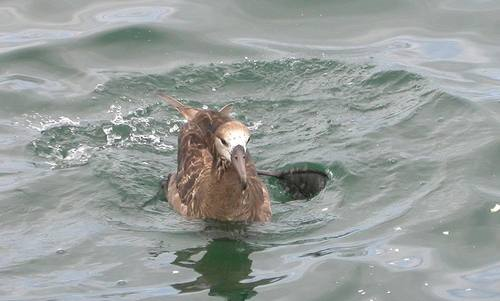

In [ ]:
%cd /content/Deep-project

from datasets import load_dataset
from PIL import Image

print("Loading CUB training dataset...")
train_dataset = load_dataset(
    "Multimodal-Fatima/CUB_train",
    split="train"
)

print("\nLoading CUB test dataset...")
test_dataset = load_dataset(
    "Multimodal-Fatima/CUB_test",
    split="test"
)

print("\n--- Dataset information ---")
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Training columns:", train_dataset.column_names)
print("Test columns:", test_dataset.column_names)

print("\n--- First training example ---")
sample = train_dataset[0]
print("Available keys:", sample.keys())
print("Label:", sample.get("label"))
print("Image type:", type(sample.get("image")))

image = sample["image"]
if isinstance(image, Image.Image):
    print("Image size:", image.size)
    display(image)
else:
    print("Image value:", str(image)[:200])

In [ ]:
%cd /content/Deep-project

import pandas as pd

splits = pd.read_csv("outputs/eda/splits.csv")

print("Saved partition counts:")
print(splits["partition"].value_counts())
print("\nSource split counts:")
print(splits["split"].value_counts())
print("\nTraining dataset length:", len(train_dataset))
print("Test dataset length:", len(test_dataset))

# Check that every saved index points to the expected image and label
errors = []

for _, row in splits.iterrows():
    source = train_dataset if row["split"] == "train" else test_dataset
    idx = int(row["index"])

    if idx < 0 or idx >= len(source):
        errors.append(f"Invalid index: {row['split']} index={idx}")
        continue

    record = source[idx]

    if int(record["label"]) != int(row["label"]):
        errors.append(
            f"Label mismatch at {row['split']} index {idx}: "
            f"CSV={row['label']}, dataset={record['label']}"
        )

    if str(record["id"]) != str(row["id"]):
        errors.append(
            f"ID mismatch at {row['split']} index {idx}: "
            f"CSV={row['id']}, dataset={record['id']}"
        )

print("\n--- Verification result ---")
print("Number of mismatches:", len(errors))
for error in errors[:10]:
    print(error)

if not errors:
    print("All saved indices, IDs, and labels match!")

/content/Deep-project
Saved partition counts:
partition
test          5794
train         5092
validation     899
Name: count, dtype: int64

Source split counts:
split
train    5991
test     5794
Name: count, dtype: int64

Training dataset length: 5994
Test dataset length: 5794

--- Verification result ---
Number of mismatches: 0
All saved indices, IDs, and labels match!


In [ ]:
%cd /content/Deep-project

!python -m pytest tests/test_transfer_learning.py -v

/content/Deep-project
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Deep-project
plugins: platformdirs-4.13.5, typeguard-4.6.0, langsmith-0.14.12, anyio-4.15.1
collected 2 items                                                              

tests/test_transfer_learning.py::TransferModelTests::test_feature_extraction_freezes_backbone PASSED [ 50%]
tests/test_transfer_learning.py::TransferModelTests::test_model_factories_return_200_class_logits PASSED [100%]

============================== 2 passed in 4.93s ===============================


In [ ]:
%cd /content/Deep-project

print("========== MODEL IMPLEMENTATION ==========")
!sed -n '1,260p' src/models/transfer_learning.py

print("\n========== TRAINING IMPLEMENTATION ==========")
!sed -n '1,300p' src/training/transfer_learning.py

print("\n========== TRANSFER-LEARNING GUIDE ==========")
!sed -n '1,220p' TRANSFER_LEARNING.md

/content/Deep-project
========== MODEL IMPLEMENTATION ==========
"""Torchvision ImageNet model factories for CUB transfer learning."""

from __future__ import annotations

from torch import nn
from torchvision.models import (
    EfficientNet_B3_Weights,
    ResNet50_Weights,
    efficientnet_b3,
    resnet50,
)


MODEL_SPECS = {
    "resnet50": (ResNet50_Weights.DEFAULT, 224),
    "efficientnet_b3": (EfficientNet_B3_Weights.DEFAULT, 300),
}


def create_transfer_model(model_name: str, num_classes: int = 200, pretrained: bool = True):
    """Return a pretrained model, its weights enum, and its recommended crop size."""
    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT
        model = resnet50(weights=weights if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "efficientnet_b3":
        weights = EfficientNet_B3_Weights.DEFAULT
        model = efficientnet_b3(weights=weights if pretrained else None)
  

In [ ]:
%cd /content/Deep-project

from pathlib import Path
import yaml
import torch
from torch import nn
from torch.utils.data import DataLoader

from src.models.transfer_learning import (
    create_transfer_model,
    configure_trainable_layers,
)
from src.data.transfer_dataset import load_transfer_splits

# Load configuration
root = Path.cwd()
config = yaml.safe_load(
    (root / "configs/transfer_learning.yaml").read_text()
)

# Confirm GPU
assert torch.cuda.is_available(), "CUDA GPU is not available."
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained ResNet-50 and prepare its classification head
model, weights = create_transfer_model("resnet50", num_classes=200)
configure_trainable_layers(
    model, "resnet50", stage="feature_extraction"
)

# Load the existing project splits
data, _ = load_transfer_splits(config, root, weights)
loader = DataLoader(data["train"], batch_size=2, shuffle=False, num_workers=0)

images, labels, sample_ids = next(iter(loader))
print("Image batch shape:", tuple(images.shape))
print("Labels shape:", tuple(labels.shape))

model = model.to(device)
images = images.to(device)
labels = labels.to(device)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.001,
)
criterion = nn.CrossEntropyLoss()

# One training step with mixed precision on the GPU
model.train()
optimizer.zero_grad(set_to_none=True)

with torch.autocast(device_type="cuda", dtype=torch.float16):
    logits = model(images)
    loss = criterion(logits, labels)

loss.backward()
optimizer.step()

print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 4))
print("Smoke test PASSED!")

/content/Deep-project
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 83.0MB/s]


Image batch shape: (2, 3, 224, 224)
Labels shape: (2,)
Output shape: (2, 200)
Loss: 5.3164
Smoke test PASSED!


In [ ]:
%cd /content/Deep-project

!python -u -m src.training.transfer_learning train \
    --model resnet50 \
    --stage feature_extraction \
    --device cuda \
    --batch-size 32

/content/Deep-project
/content/Deep-project/src/training/transfer_learning.py:167: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
resnet50 feature_extraction epoch 1/30: train loss 4.6023, val loss 3.7126, train acc 0.1196, val acc 0.3181, lr [0.001], 46.1s
resnet50 feature_extraction epoch 2/30: train loss 3.3061, val loss 3.2174, train acc 0.4016, val acc 0.4227, lr [0.001], 46.7s
resnet50 feature_extraction epoch 3/30: train loss 2.6772, val loss 2.6363, train acc 0.5245, val acc 0.4583, lr [0.001], 44.6s
resnet50 feature_extraction epoch 4/30: train loss 2.2382, val loss 2.3779, train acc 0.5970, val acc 0.4928, lr [0.001], 44.5s
resnet50 feature_extraction epoch 5/30: train loss 1.9832, val loss 2.2613, train acc 0.6390, val acc 0.5050, lr [0.001], 44.4s
resnet50 feature_extraction epoch 6/30: train loss 1.7386, val loss 2.0644, train acc 0.6840, va

In [ ]:

%cd /content/Deep-project

!python -u -m src.training.transfer_learning train \
    --model resnet50 \
    --stage fine_tuning \
    --init-checkpoint outputs/transfer_learning/resnet50/feature_extraction/best_checkpoint.pth \
    --device cuda \
    --batch-size 32


/content/Deep-project
/content/Deep-project/src/training/transfer_learning.py:167: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
resnet50 fine_tuning epoch 1/30: train loss 0.4879, val loss 1.3752, train acc 0.9048, val acc 0.6196, lr [0.0001, 1e-05], 49.5s
resnet50 fine_tuning epoch 2/30: train loss 0.4890, val loss 1.3138, train acc 0.8908, val acc 0.6429, lr [0.0001, 1e-05], 48.2s
resnet50 fine_tuning epoch 3/30: train loss 0.4636, val loss 1.3138, train acc 0.9016, val acc 0.6396, lr [0.0001, 1e-05], 47.9s
resnet50 fine_tuning epoch 4/30: train loss 0.4178, val loss 1.3292, train acc 0.9059, val acc 0.6374, lr [0.0001, 1e-05], 47.6s
resnet50 fine_tuning epoch 5/30: train loss 0.4172, val loss 1.3138, train acc 0.9042, val acc 0.6352, lr [2e-05, 2.0000000000000003e-06], 47.9s
resnet50 fine_tuning epoch 6/30: train loss 0.3753, val loss 1.2984, train 

In [ ]:

%cd /content/Deep-project

!python -u -m src.training.transfer_learning train \
    --model efficientnet_b3 \
    --stage feature_extraction \
    --device cuda \
    --batch-size 32


/content/Deep-project
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth
100% 47.2M/47.2M [00:00<00:00, 175MB/s]
/content/Deep-project/src/training/transfer_learning.py:167: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
efficientnet_b3 feature_extraction epoch 1/30: train loss 4.5980, val loss 3.5142, train acc 0.1528, val acc 0.4538, lr [0.001], 74.5s
efficientnet_b3 feature_extraction epoch 2/30: train loss 3.2548, val loss 2.6404, train acc 0.4287, val acc 0.5261, lr [0.001], 71.1s
efficientnet_b3 feature_extraction epoch 3/30: train loss 2.5578, val loss 2.1376, train acc 0.5391, val acc 0.5818, lr [0.001], 70.7s
efficientnet_b3 feature_extraction epoch 4/30: train loss 2.1398, val loss 1.8752, train acc 0.6060, val acc 0.6174, lr [0.0

In [ ]:

%cd /content/Deep-project

!python -u -m src.training.transfer_learning train \
    --model efficientnet_b3 \
    --stage fine_tuning \
    --init-checkpoint outputs/transfer_learning/efficientnet_b3/feature_extraction/best_checkpoint.pth \
    --device cuda \
    --batch-size 32


/content/Deep-project
/content/Deep-project/src/training/transfer_learning.py:167: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
efficientnet_b3 fine_tuning epoch 1/30: train loss 0.7077, val loss 1.1624, train acc 0.8559, val acc 0.6885, lr [0.0001, 1e-05], 73.4s
efficientnet_b3 fine_tuning epoch 2/30: train loss 0.7152, val loss 1.1879, train acc 0.8521, val acc 0.6785, lr [0.0001, 1e-05], 71.3s
efficientnet_b3 fine_tuning epoch 3/30: train loss 0.7177, val loss 1.1288, train acc 0.8594, val acc 0.6830, lr [0.0001, 1e-05], 71.4s
efficientnet_b3 fine_tuning epoch 4/30: train loss 0.6990, val loss 1.1418, train acc 0.8588, val acc 0.6819, lr [0.0001, 1e-05], 71.0s
efficientnet_b3 fine_tuning epoch 5/30: train loss 0.7130, val loss 1.1853, train acc 0.8598, val acc 0.6796, lr [0.0001, 1e-05], 71.1s
efficientnet_b3 fine_tuning epoch 6/30: train loss 0.686

In [ ]:

%cd /content/Deep-project

!python -m src.training.transfer_learning evaluate \
    --model resnet50 \
    --checkpoint outputs/transfer_learning/resnet50/fine_tuning/best_checkpoint.pth

!python -m src.training.transfer_learning evaluate \
    --model efficientnet_b3 \
    --checkpoint outputs/transfer_learning/efficientnet_b3/feature_extraction/best_checkpoint.pth


/content/Deep-project
{
  "model": "resnet50",
  "checkpoint": "outputs/transfer_learning/resnet50/fine_tuning/best_checkpoint.pth",
  "best_validation_accuracy": 0.64293659621802,
  "best_validation_loss": 1.3138412013732816,
  "best_epoch": 2,
  "test_accuracy": 0.6632723507076286,
  "test_loss": 1.2528096201669194,
  "macro_precision": 0.6723409419848079,
  "macro_recall": 0.6655864937358862,
  "macro_f1": 0.6623962374365366,
  "weighted_precision": 0.669675773265963,
  "weighted_recall": 0.6632723507076286,
  "weighted_f1": 0.6598517741765797,
  "test_samples": 5794,
  "total_training_seconds": 1549.532175673999,
  "test_inference_seconds_end_to_end": 47.967455476000396,
  "test_inference_seconds_per_image": 0.0082788152357612,
  "test_timing_method": "wall-clock around the full DataLoader iteration, including preprocessing and transfers; CUDA synchronized at end",
  "input_crop_size": 224,
  "averaging_methods": "macro and weighted; per-class scores are one-vs-rest"
}
{
  "model":

In [ ]:

%cd /content/Deep-project

!pip -q install transformers accelerate

from transformers import AutoConfig, AutoImageProcessor

model_id = "HaotianZG/vit-cub-200-2011-bird"

config = AutoConfig.from_pretrained(model_id)
processor = AutoImageProcessor.from_pretrained(model_id)

print("Number of classes:", config.num_labels)
print("Model architecture:", config.architectures)
print("Image size:", processor.size)
print("\nFirst 15 class labels:")

for i, label in list(config.id2label.items())[:15]:
    print(i, ":", label)


/content/Deep-project


config.json:   0%|          | 0.00/69.8k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Number of classes: 1000
Model architecture: ['ViTForImageClassification']
Image size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)

First 15 class labels:
0 : tench, Tinca tinca
1 : goldfish, Carassius auratus
2 : great white shark, white shark, man-eater, man-eating shark, Carcharodon carcharias
3 : tiger shark, Galeocerdo cuvieri
4 : hammerhead, hammerhead shark
5 : electric ray, crampfish, numbfish, torpedo
6 : stingray
7 : cock
8 : hen
9 : ostrich, Struthio camelus
10 : brambling, Fringilla montifringilla
11 : goldfinch, Carduelis carduelis
12 : house finch, linnet, Carpodacus mexicanus
13 : junco, snowbird
14 : indigo bunting, indigo finch, indigo bird, Passerina cyanea


In [ ]:
from pathlib import Path

root = Path("/content/Deep-project")

for path in sorted(root.glob("outputs/transfer_learning/**/*")):
    if path.is_file() and any(
        word in path.name.lower()
        for word in ["class", "metric", "prediction"]
    ):
        print(path.relative_to(root))

outputs/transfer_learning/efficientnet_b3/class_mapping.json
outputs/transfer_learning/efficientnet_b3/evaluation_metrics.json
outputs/transfer_learning/efficientnet_b3/per_class_metrics.csv
outputs/transfer_learning/efficientnet_b3/test_predictions.csv
outputs/transfer_learning/resnet50/class_mapping.json
outputs/transfer_learning/resnet50/evaluation_metrics.json
outputs/transfer_learning/resnet50/per_class_metrics.csv
outputs/transfer_learning/resnet50/test_predictions.csv


In [ ]:
import json
from pathlib import Path

root = Path("/content/Deep-project/outputs/transfer_learning")

for model in ["resnet50", "efficientnet_b3"]:
    path = root / model / "class_mapping.json"

    print(f"\n--- {model} ---")
    with open(path, "r") as f:
        mapping = json.load(f)

    print("Mapping type:", type(mapping).__name__)
    if isinstance(mapping, dict):
        print("Number of entries:", len(mapping))
        print("First 10 entries:")
        for i, (key, value) in enumerate(mapping.items()):
            if i == 10:
                break
            print(key, ":", value)
    else:
        print("First 10 entries:", mapping[:10])


--- resnet50 ---
Mapping type: dict
Number of entries: 200
First 10 entries:
0 : 0
1 : 1
2 : 2
3 : 3
4 : 4
5 : 5
6 : 6
7 : 7
8 : 8
9 : 9

--- efficientnet_b3 ---
Mapping type: dict
Number of entries: 200
First 10 entries:
0 : 0
1 : 1
2 : 2
3 : 3
4 : 4
5 : 5
6 : 6
7 : 7
8 : 8
9 : 9


In [ ]:
import pandas as pd
import json
from pathlib import Path

root = Path("/content/Deep-project")

splits = pd.read_csv(root / "outputs/eda/splits.csv")

print("Split columns:", splits.columns.tolist())
print("\nFirst 10 rows:")
print(splits[["label", "file_name"]].head(10).to_string(index=False))

print("\nUnique labels:", splits["label"].nunique())
print("Minimum label:", splits["label"].min())
print("Maximum label:", splits["label"].max())

for model in ["resnet50", "efficientnet_b3"]:
    path = root / "outputs/transfer_learning" / model / "class_mapping.json"
    with open(path, "r") as f:
        mapping = json.load(f)
    print(f"\n{model} mapping sample:", list(mapping.items())[:5])

Split columns: ['partition', 'split', 'index', 'id', 'file_name', 'label']

First 10 rows:
 label                                file_name
    80           Pied_Kingfisher_0040_72739.jpg
   183    Louisiana_Waterthrush_0056_795245.jpg
    44           Northern_Fulmar_0048_43672.jpg
    60             Heermann_Gull_0115_45797.jpg
   160      Blue_Winged_Warbler_0023_161774.jpg
    49               Eared_Grebe_0040_34340.jpg
    76         Tropical_Kingbird_0057_69283.jpg
    18              Gray_Catbird_0050_20763.jpg
    17          Spotted_Catbird_0004_796804.jpg
    40 Scissor_Tailed_Flycatcher_0106_41684.jpg

Unique labels: 200
Minimum label: 0
Maximum label: 199

resnet50 mapping sample: [('0', 0), ('1', 1), ('2', 2), ('3', 3), ('4', 4)]

efficientnet_b3 mapping sample: [('0', 0), ('1', 1), ('2', 2), ('3', 3), ('4', 4)]


In [ ]:
import pandas as pd
import json
from pathlib import Path

root = Path("/content/Deep-project")
splits = pd.read_csv(root / "outputs/eda/splits.csv")

# Show the species filenames associated with each numeric label
species_by_label = (
    splits.assign(
        species=splits["file_name"].str.rsplit("_", n=2).str[0]
    )
    .groupby("label")["species"]
    .agg(lambda x: sorted(set(x)))
)

print("First 20 labels and their species names:")
for label, species in species_by_label.head(20).items():
    print(f"{label}: {species}")

print("\nLabels associated with more than one species name:")
print(species_by_label[species_by_label.apply(len) > 1])

First 20 labels and their species names:
0: ['Black_Footed_Albatross']
1: ['Laysan_Albatross']
2: ['Sooty_Albatross']
3: ['Groove_Billed_Ani']
4: ['Crested_Auklet']
5: ['Least_Auklet']
6: ['Parakeet_Auklet']
7: ['Rhinoceros_Auklet']
8: ['Brewer_Blackbird']
9: ['Red_Winged_Blackbird']
10: ['Rusty_Blackbird']
11: ['Yellow_Headed_Blackbird']
12: ['Bobolink']
13: ['Indigo_Bunting']
14: ['Lazuli_Bunting']
15: ['Painted_Bunting']
16: ['Cardinal']
17: ['Spotted_Catbird']
18: ['Gray_Catbird']
19: ['Yellow_Breasted_Chat']

Labels associated with more than one species name:
Series([], Name: species, dtype: object)


In [ ]:
%cd /content/Deep-project

!python -m src.training.transfer_learning evaluate \
  --model resnet50 \
  --checkpoint outputs/transfer_learning/resnet50/feature_extraction/best_checkpoint.pth

/content/Deep-project
{
  "model": "resnet50",
  "checkpoint": "outputs/transfer_learning/resnet50/feature_extraction/best_checkpoint.pth",
  "best_validation_accuracy": 0.6084538375973304,
  "best_validation_loss": 1.5775830585248478,
  "best_epoch": 18,
  "test_accuracy": 0.6075250258888505,
  "test_loss": 1.5380903082055226,
  "macro_precision": 0.6287700974017955,
  "macro_recall": 0.6107089072495843,
  "macro_f1": 0.6079670105660863,
  "weighted_precision": 0.6255746414269666,
  "weighted_recall": 0.6075250258888505,
  "weighted_f1": 0.6046273770324301,
  "test_samples": 5794,
  "total_training_seconds": 1116.3205986459984,
  "test_inference_seconds_end_to_end": 47.37158297899987,
  "test_inference_seconds_per_image": 0.008175972209009298,
  "test_timing_method": "wall-clock around the full DataLoader iteration, including preprocessing and transfers; CUDA synchronized at end",
  "input_crop_size": 224,
  "averaging_methods": "macro and weighted; per-class scores are one-vs-rest"
}

In [ ]:
%cd /content/Deep-project

!python -m src.training.transfer_learning evaluate \
  --model efficientnet_b3 \
  --checkpoint outputs/transfer_learning/efficientnet_b3/fine_tuning/best_checkpoint.pth

/content/Deep-project
{
  "model": "efficientnet_b3",
  "checkpoint": "outputs/transfer_learning/efficientnet_b3/fine_tuning/best_checkpoint.pth",
  "best_validation_accuracy": 0.6885428253615128,
  "best_validation_loss": 1.1623629930287236,
  "best_epoch": 1,
  "test_accuracy": 0.7024508111839834,
  "test_loss": 1.210274048990573,
  "macro_precision": 0.7107834277262646,
  "macro_recall": 0.7044200321357862,
  "macro_f1": 0.7030006900122103,
  "weighted_precision": 0.7088698565926151,
  "weighted_recall": 0.7024508111839834,
  "weighted_f1": 0.7011142900456788,
  "test_samples": 5794,
  "total_training_seconds": 2684.4204768060035,
  "test_inference_seconds_end_to_end": 75.54191605300002,
  "test_inference_seconds_per_image": 0.013037955825509151,
  "test_timing_method": "wall-clock around the full DataLoader iteration, including preprocessing and transfers; CUDA synchronized at end",
  "input_crop_size": 300,
  "averaging_methods": "macro and weighted; per-class scores are one-vs-re

In [ ]:
import json
import pandas as pd
from pathlib import Path

root = Path("/content/Deep-project/outputs/transfer_learning")

experiments = [
    ("ResNet-50", "Feature extraction", "resnet50/feature_extraction"),
    ("ResNet-50", "Fine-tuning", "resnet50/fine_tuning"),
    ("EfficientNet-B3", "Feature extraction", "efficientnet_b3/feature_extraction"),
    ("EfficientNet-B3", "Fine-tuning", "efficientnet_b3/fine_tuning"),
]

rows = []

for model, stage, folder in experiments:
    path = root / folder / "evaluation_metrics.json"

    if not path.exists():
        print("Missing evaluation file:", path)
        continue

    with open(path, "r") as f:
        metrics = json.load(f)

    rows.append({
        "Model": model,
        "Stage": stage,
        "Best Validation Accuracy": metrics["best_validation_accuracy"],
        "Test Accuracy": metrics["test_accuracy"],
        "Test Loss": metrics["test_loss"],
        "Macro Precision": metrics["macro_precision"],
        "Macro Recall": metrics["macro_recall"],
        "Macro F1": metrics["macro_f1"],
        "Weighted F1": metrics["weighted_f1"],
        "Training Seconds": metrics["total_training_seconds"],
    })

comparison = pd.DataFrame(rows)
display(comparison)

output_path = root / "comparison_all_experiments.csv"
comparison.to_csv(output_path, index=False)

print("\nSaved comparison to:", output_path)
print("Experiments included:", len(comparison))

Missing evaluation file: /content/Deep-project/outputs/transfer_learning/resnet50/feature_extraction/evaluation_metrics.json
Missing evaluation file: /content/Deep-project/outputs/transfer_learning/resnet50/fine_tuning/evaluation_metrics.json
Missing evaluation file: /content/Deep-project/outputs/transfer_learning/efficientnet_b3/feature_extraction/evaluation_metrics.json
Missing evaluation file: /content/Deep-project/outputs/transfer_learning/efficientnet_b3/fine_tuning/evaluation_metrics.json


""



Saved comparison to: /content/Deep-project/outputs/transfer_learning/comparison_all_experiments.csv
Experiments included: 0


In [ ]:
from pathlib import Path

root = Path("/content/Deep-project")

print("Evaluation metric files:")
for path in sorted(root.glob("outputs/transfer_learning/**/evaluation_metrics.json")):
    print(path.relative_to(root))

print("\nAll JSON files under transfer_learning:")
for path in sorted(root.glob("outputs/transfer_learning/**/*.json")):
    print(path.relative_to(root))

Evaluation metric files:
outputs/transfer_learning/efficientnet_b3/evaluation_metrics.json
outputs/transfer_learning/resnet50/evaluation_metrics.json

All JSON files under transfer_learning:
outputs/transfer_learning/efficientnet_b3/class_mapping.json
outputs/transfer_learning/efficientnet_b3/evaluation_metrics.json
outputs/transfer_learning/resnet50/class_mapping.json
outputs/transfer_learning/resnet50/evaluation_metrics.json


In [ ]:

import pandas as pd
from pathlib import Path

root = Path("/content/Deep-project/outputs/transfer_learning")

results = [
    {
        "Model": "ResNet-50",
        "Stage": "Feature Extraction",
        "Best Epoch": 18,
        "Best Validation Accuracy (%)": 60.85,
        "Test Accuracy (%)": 60.75,
        "Test Loss": 1.5381,
        "Macro Precision (%)": 62.88,
        "Macro Recall (%)": 61.07,
        "Macro F1 (%)": 60.80,
        "Training Time (s)": 1116.32,
        "Inference Time/Image (s)": 0.00818,
    },
    {
        "Model": "ResNet-50",
        "Stage": "Fine-Tuning",
        "Best Epoch": 2,
        "Best Validation Accuracy (%)": 64.29,
        "Test Accuracy (%)": 66.33,
        "Test Loss": 1.2528,
        "Macro Precision (%)": 67.23,
        "Macro Recall (%)": 66.56,
        "Macro F1 (%)": 66.24,
        "Training Time (s)": 1549.53,
        "Inference Time/Image (s)": 0.00828,
    },
    {
        "Model": "EfficientNet-B3",
        "Stage": "Feature Extraction",
        "Best Epoch": 23,
        "Best Validation Accuracy (%)": 69.30,
        "Test Accuracy (%)": 70.37,
        "Test Loss": 1.8254,
        "Macro Precision (%)": 71.23,
        "Macro Recall (%)": 70.54,
        "Macro F1 (%)": 70.36,
        "Training Time (s)": 2112.90,
        "Inference Time/Image (s)": 0.01309,
    },
    {
        "Model": "EfficientNet-B3",
        "Stage": "Fine-Tuning",
        "Best Epoch": 1,
        "Best Validation Accuracy (%)": 68.85,
        "Test Accuracy (%)": 70.25,
        "Test Loss": 1.2103,
        "Macro Precision (%)": 71.08,
        "Macro Recall (%)": 70.44,
        "Macro F1 (%)": 70.30,
        "Training Time (s)": 2684.42,
        "Inference Time/Image (s)": 0.01304,
    },
]

df = pd.DataFrame(results)

output_path = root / "comparison_all_experiments.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)

display(df.round(2))

print(f"\nComparison saved to: {output_path}")


,Model,Stage,Best Epoch,Best Validation Accuracy (%),Test Accuracy (%),Test Loss,Macro Precision (%),Macro Recall (%),Macro F1 (%),Training Time (s),Inference Time/Image (s)
0,ResNet-50,Feature Extraction,18,60.85,60.75,1.54,62.88,61.07,60.80,1116.32,0.01
1,ResNet-50,Fine-Tuning,2,64.29,66.33,1.25,67.23,66.56,66.24,1549.53,0.01
2,EfficientNet-B3,Feature Extraction,23,69.30,70.37,1.83,71.23,70.54,70.36,2112.90,0.01
3,EfficientNet-B3,Fine-Tuning,1,68.85,70.25,1.21,71.08,70.44,70.30,2684.42,0.01



Comparison saved to: /content/Deep-project/outputs/transfer_learning/comparison_all_experiments.csv


In [ ]:

from pathlib import Path

root = Path("/content/Deep-project/outputs/transfer_learning")

for path in sorted(root.rglob("*")):
    if path.is_file():
        print(path.relative_to(root))


comparison.csv
comparison_all_experiments.csv
efficientnet_b3/class_mapping.json
efficientnet_b3/confusion_matrix.csv
efficientnet_b3/evaluation_metrics.json
efficientnet_b3/feature_extraction/best_checkpoint.pth
efficientnet_b3/feature_extraction/history.csv
efficientnet_b3/feature_extraction/training_curves.png
efficientnet_b3/fine_tuning/best_checkpoint.pth
efficientnet_b3/fine_tuning/history.csv
efficientnet_b3/fine_tuning/training_curves.png
efficientnet_b3/per_class_metrics.csv
efficientnet_b3/test_predictions.csv
resnet50/class_mapping.json
resnet50/confusion_matrix.csv
resnet50/evaluation_metrics.json
resnet50/feature_extraction/best_checkpoint.pth
resnet50/feature_extraction/history.csv
resnet50/feature_extraction/training_curves.png
resnet50/fine_tuning/best_checkpoint.pth
resnet50/fine_tuning/history.csv
resnet50/fine_tuning/training_curves.png
resnet50/per_class_metrics.csv
resnet50/test_predictions.csv
results_summary.md


In [ ]:

from pathlib import Path

summary_path = Path(
    "/content/Deep-project/outputs/transfer_learning/results_summary.md"
)

print(summary_path.read_text())


# Transfer-learning results

See `comparison.csv` and each model's `evaluation_metrics.json`. Checkpoints are selected by validation accuracy; the held-out test split is evaluated only by the explicit evaluate command. The scratch baseline row contains only metrics recorded in its README; precision, recall, F1, predictions, and timing are unavailable for that run. Inference timing is end-to-end across DataLoader iteration, including preprocessing and device transfer.



In [ ]:

from pathlib import Path

summary_path = Path(
    "/content/Deep-project/outputs/transfer_learning/results_summary.md"
)

summary = """# Transfer-Learning Results

## 1. Objective

This experiment compares ResNet-50 and EfficientNet-B3 for the
200-class CUB-200-2011 bird species classification task.

Two transfer-learning strategies were evaluated for each model:
- Feature extraction: freeze the pretrained backbone and train the classifier.
- Fine-tuning: train the classifier and selected backbone layers.

## 2. Experimental Results

All four checkpoints were selected using validation accuracy.
The held-out test set contains 5,794 images.

| Model | Stage | Best Epoch | Best Validation Accuracy | Test Accuracy | Macro F1 |
|---|---|---:|---:|---:|---:|
| ResNet-50 | Feature extraction | 18 | 60.85% | 60.75% | 60.80% |
| ResNet-50 | Fine-tuning | 2 | 64.29% | 66.33% | 66.24% |
| EfficientNet-B3 | Feature extraction | 23 | 69.30% | 70.37% | 70.36% |
| EfficientNet-B3 | Fine-tuning | 1 | 68.85% | 70.25% | 70.30% |

## 3. Discussion

EfficientNet-B3 with feature extraction achieved the highest test
accuracy (70.37%) and macro F1-score (70.36%) among these four runs.

Fine-tuning improved ResNet-50's test accuracy from 60.75% to 66.33%.
For EfficientNet-B3, fine-tuning produced a slightly lower test accuracy
than feature extraction (70.25% versus 70.37%).

These findings describe the experiments conducted; they do not establish
that one architecture or training strategy will always perform best.

## 4. Timing

| Model | Stage | Training Time (seconds) | End-to-End Inference Time per Image (seconds) |
|---|---|---:|---:|
| ResNet-50 | Feature extraction | 1116.32 | 0.00818 |
| ResNet-50 | Fine-tuning | 1549.53 | 0.00828 |
| EfficientNet-B3 | Feature extraction | 2112.90 | 0.01309 |
| EfficientNet-B3 | Fine-tuning | 2684.42 | 0.01304 |

Inference timing includes DataLoader iteration, preprocessing, and device
transfer. These timings are specific to the recorded environment.

## 5. Output Files

Each model folder contains its class mapping, evaluation metrics,
confusion matrix, per-class metrics, and test predictions.
Each experiment folder contains its best checkpoint, training history,
and training-curve plot.

- `comparison.csv`
- `comparison_all_experiments.csv`
- `results_summary.md`

The scratch-baseline row, if included in the comparison, has only the
metrics recorded in its README. Precision, recall, F1, predictions, and
timing are unavailable for that run.
"""

summary_path.write_text(summary, encoding="utf-8")
print(summary_path.read_text(encoding="utf-8"))
print("\nSummary updated successfully.")


# Transfer-Learning Results

## 1. Objective

This experiment compares ResNet-50 and EfficientNet-B3 for the
200-class CUB-200-2011 bird species classification task.

Two transfer-learning strategies were evaluated for each model:
- Feature extraction: freeze the pretrained backbone and train the classifier.
- Fine-tuning: train the classifier and selected backbone layers.

## 2. Experimental Results

All four checkpoints were selected using validation accuracy.
The held-out test set contains 5,794 images.

| Model | Stage | Best Epoch | Best Validation Accuracy | Test Accuracy | Macro F1 |
|---|---|---:|---:|---:|---:|
| ResNet-50 | Feature extraction | 18 | 60.85% | 60.75% | 60.80% |
| ResNet-50 | Fine-tuning | 2 | 64.29% | 66.33% | 66.24% |
| EfficientNet-B3 | Feature extraction | 23 | 69.30% | 70.37% | 70.36% |
| EfficientNet-B3 | Fine-tuning | 1 | 68.85% | 70.25% | 70.30% |

## 3. Discussion

EfficientNet-B3 with feature extraction achieved the highest test
accuracy (70.37%) and m

In [ ]:

from pathlib import Path
import shutil

project_root = Path("/content/Deep-project")
output_dir = project_root / "outputs" / "transfer_learning"

# Include the code and configuration needed to reproduce your experiments.
backup_items = [
    project_root / "src" / "training" / "transfer_learning.py",
    project_root / "configs" / "transfer_learning.yaml",
    project_root / "tests" / "test_transfer_learning.py",
    output_dir,
]

backup_dir = Path("/content/transfer_learning_backup")
backup_dir.mkdir(parents=True, exist_ok=True)

for item in backup_items:
    if not item.exists():
        print(f"Not found (check this): {item}")
        continue

    destination = backup_dir / item.name

    if item.is_dir():
        shutil.copytree(item, destination, dirs_exist_ok=True)
    else:
        shutil.copy2(item, destination)

zip_path = shutil.make_archive(
    "/content/transfer_learning_backup",
    "zip",
    root_dir=backup_dir
)

print("Backup created:", zip_path)
print("Size (MB):", round(Path(zip_path).stat().st_size / (1024 * 1024), 2))


Backup created: /content/transfer_learning_backup.zip
Size (MB): 249.2


In [ ]:

from google.colab import files
files.download("/content/transfer_learning_backup.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/Deep-project

/content/Deep-project


In [ ]:
%cd /content/Deep-project

/content/Deep-project


In [ ]:
!python -m src.training.transfer_learning evaluate --model resnet50 --checkpoint outputs/transfer_learning/resnet50/fine_tuning/best_checkpoint.pth

{
  "model": "resnet50",
  "checkpoint": "outputs/transfer_learning/resnet50/fine_tuning/best_checkpoint.pth",
  "best_validation_accuracy": 0.64293659621802,
  "best_validation_loss": 1.3138412013732816,
  "best_epoch": 2,
  "test_accuracy": 0.6632723507076286,
  "test_loss": 1.2528096201669194,
  "macro_precision": 0.6723409419848079,
  "macro_recall": 0.6655864937358862,
  "macro_f1": 0.6623962374365366,
  "weighted_precision": 0.669675773265963,
  "weighted_recall": 0.6632723507076286,
  "weighted_f1": 0.6598517741765797,
  "test_samples": 5794,
  "total_training_seconds": 1549.532175673999,
  "test_inference_seconds_end_to_end": 47.43219577399941,
  "test_inference_seconds_per_image": 0.008186433512944324,
  "test_timing_method": "wall-clock around the full DataLoader iteration, including preprocessing and transfers; CUDA synchronized at end",
  "input_crop_size": 224,
  "averaging_methods": "macro and weighted; per-class scores are one-vs-rest"
}


In [ ]:
!python -m src.training.transfer_learning evaluate --model efficientnet_b3 --checkpoint outputs/transfer_learning/efficientnet_b3/feature_extraction/best_checkpoint.pth

{
  "model": "efficientnet_b3",
  "checkpoint": "outputs/transfer_learning/efficientnet_b3/feature_extraction/best_checkpoint.pth",
  "best_validation_accuracy": 0.692992213570634,
  "best_validation_loss": 1.190702788424041,
  "best_epoch": 23,
  "test_accuracy": 0.7036589575422851,
  "test_loss": 1.825416391456296,
  "macro_precision": 0.7123404452203558,
  "macro_recall": 0.7054275490781055,
  "macro_f1": 0.7035824490777578,
  "weighted_precision": 0.7110558206414783,
  "weighted_recall": 0.7036589575422851,
  "weighted_f1": 0.702050992221311,
  "test_samples": 5794,
  "total_training_seconds": 2112.8990415820035,
  "test_inference_seconds_end_to_end": 75.94474996899953,
  "test_inference_seconds_per_image": 0.013107481872454183,
  "test_timing_method": "wall-clock around the full DataLoader iteration, including preprocessing and transfers; CUDA synchronized at end",
  "input_crop_size": 300,
  "averaging_methods": "macro and weighted; per-class scores are one-vs-rest"
}


In [ ]:
import shutil
from pathlib import Path

project = Path("/content/Deep-project")
results = project / "outputs" / "transfer_learning"
zip_path = Path("/content/transfer_learning_results_updated.zip")

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=project / "outputs",
    base_dir="transfer_learning"
)

print(f"ZIP created: {zip_path}")
print(f"ZIP size: {zip_path.stat().st_size / (1024 * 1024):.2f} MB")

ZIP created: /content/transfer_learning_results_updated.zip
ZIP size: 249.19 MB


In [ ]:
from google.colab import files
files.download("/content/transfer_learning_results_updated.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>